In [2]:
import pandas as pd
print("pandas version:", pd.__version__)

pandas version: 3.0.6


In [3]:
import os
print(os.getcwd())

C:\Users\Nikhil\aqi-forecasting-india


In [4]:
import pandas as pd

df = pd.read_csv("data/raw/city_day.csv")
print(df.shape)
df.head()

(29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [5]:
print(df["City"].nunique(), "cities")
print(df["City"].value_counts())

26 cities
City
Ahmedabad             2009
Bengaluru             2009
Chennai               2009
Delhi                 2009
Lucknow               2009
Mumbai                2009
Hyderabad             2006
Patna                 1858
Gurugram              1679
Visakhapatnam         1462
Amritsar              1221
Jorapokhar            1169
Jaipur                1114
Thiruvananthapuram    1112
Amaravati              951
Brajrajnagar           938
Talcher                925
Kolkata                814
Guwahati               502
Coimbatore             386
Shillong               310
Chandigarh             304
Bhopal                 289
Ernakulam              162
Kochi                  162
Aizawl                 113
Name: count, dtype: int64


In [6]:
df["Date"] = pd.to_datetime(df["Date"])
print("From:", df["Date"].min())
print("To:", df["Date"].max())
print("\nMissing % per column:")
print((df.isna().mean() * 100).round(1))

From: 2015-01-01 00:00:00
To: 2020-07-01 00:00:00

Missing % per column:
City           0.0
Date           0.0
PM2.5         15.6
PM10          37.7
NO            12.1
NO2           12.1
NOx           14.2
NH3           35.0
CO             7.0
SO2           13.1
O3            13.6
Benzene       19.0
Toluene       27.2
Xylene        61.3
AQI           15.9
AQI_Bucket    15.9
dtype: float64


In [7]:
missing = df.groupby("City")["AQI"].apply(lambda s: s.isna().mean() * 100).round(1)
print(missing.sort_values())

City
Delhi                  0.5
Guwahati               1.4
Chandigarh             1.6
Aizawl                 1.8
Jaipur                 1.8
Kochi                  2.5
Bhopal                 3.8
Bengaluru              4.9
Thiruvananthapuram     5.4
Ernakulam              5.6
Lucknow                5.8
Chennai                6.2
Hyderabad              6.3
Kolkata                7.4
Amritsar               7.8
Coimbatore            10.9
Amaravati             11.6
Gurugram              13.5
Visakhapatnam         19.9
Patna                 21.5
Brajrajnagar          24.0
Talcher               24.5
Ahmedabad             33.6
Shillong              33.9
Jorapokhar            34.0
Mumbai                61.4
Name: AQI, dtype: float64


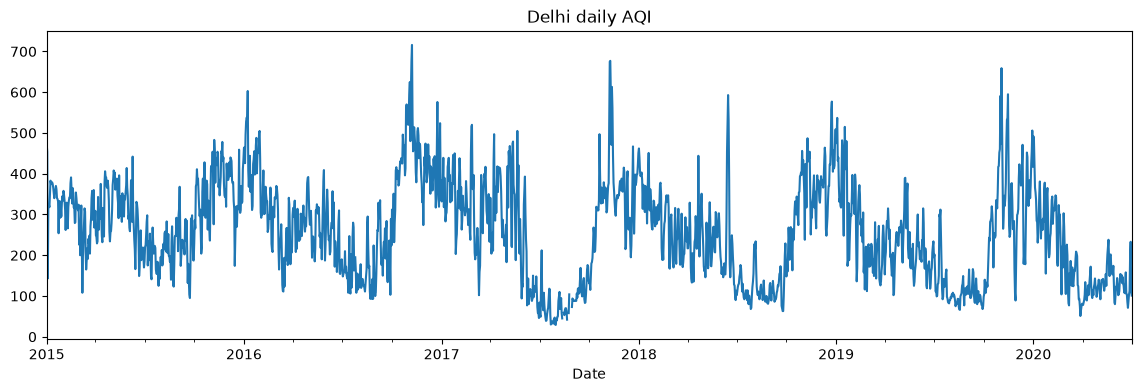

In [8]:
import matplotlib.pyplot as plt

delhi = df[df["City"] == "Delhi"].set_index("Date")["AQI"]
delhi.plot(figsize=(14, 4), title="Delhi daily AQI")
plt.show()

In [9]:
counts = df["City"].value_counts()
missing = df.groupby("City")["AQI"].apply(lambda s: s.isna().mean() * 100)

good_cities = [c for c in counts.index if counts[c] >= 1000 and missing[c] < 15]
print(len(good_cities), "cities kept:")
print(good_cities)


9 cities kept:
['Bengaluru', 'Chennai', 'Delhi', 'Lucknow', 'Hyderabad', 'Gurugram', 'Amritsar', 'Jaipur', 'Thiruvananthapuram']


In [10]:
df_clean = df[df["City"].isin(good_cities)][["City", "Date", "AQI"]].copy()
df_clean = df_clean.sort_values(["City", "Date"])

# fill short gaps (up to 3 days) within each city
df_clean["AQI"] = df_clean.groupby("City")["AQI"].transform(
    lambda s: s.interpolate(limit=3)
)

print(df_clean.isna().mean() * 100)
print(df_clean.shape)

City    0.000000
Date    0.000000
AQI     3.949103
dtype: float64
(15168, 3)


In [11]:
import os
os.makedirs("data/processed", exist_ok=True)
df_clean.to_csv("data/processed/aqi_clean.csv", index=False)
print("Saved!")

Saved!


In [12]:
city = "Delhi"
s = df_clean[df_clean["City"] == city].set_index("Date")["AQI"]
s = s.asfreq("D")   # make sure every day is present

# Baseline 1: tomorrow = today
pred_naive = s.shift(1)

# Baseline 2: tomorrow = average of the last 7 days
pred_avg7 = s.shift(1).rolling(7).mean()

# Time-based split: test on the last year only
test_mask = s.index >= "2019-07-01"

mae_naive = (s[test_mask] - pred_naive[test_mask]).abs().mean()
mae_avg7 = (s[test_mask] - pred_avg7[test_mask]).abs().mean()

print(f"{city} test period: {s[test_mask].index.min().date()} to {s[test_mask].index.max().date()}")
print("Baseline 1 (yesterday) MAE:", round(mae_naive, 1))
print("Baseline 2 (7-day average) MAE:", round(mae_avg7, 1))

Delhi test period: 2019-07-01 to 2020-07-01
Baseline 1 (yesterday) MAE: 31.7
Baseline 2 (7-day average) MAE: 47.3


In [13]:
from sklearn.linear_model import Ridge

# build a table of features for Delhi
d = s.to_frame("AQI")
for lag in [1, 2, 3, 7]:
    d[f"lag_{lag}"] = d["AQI"].shift(lag)
d["roll_7"] = d["AQI"].shift(1).rolling(7).mean()
d["month"] = d.index.month
d = d.dropna()

features = ["lag_1", "lag_2", "lag_3", "lag_7", "roll_7", "month"]
train = d[d.index < "2019-07-01"]
test = d[d.index >= "2019-07-01"]

model = Ridge()
model.fit(train[features], train["AQI"])
pred = model.predict(test[features])

mae_model = (test["AQI"] - pred).abs().mean()
print("Model MAE:", round(mae_model, 1))
print("Baseline (yesterday) MAE: 31.7")

Model MAE: 32.3
Baseline (yesterday) MAE: 31.7


In [14]:
rows = []
for h in [1, 3, 5, 7]:                      # h = how many days ahead
    d2 = s.to_frame("AQI")
    for lag in [0, 1, 2, 3, 7]:
        d2[f"lag_{lag}"] = d2["AQI"].shift(lag)
    d2["roll_7"] = d2["AQI"].rolling(7).mean()
    d2["month"] = d2.index.month
    d2["target"] = d2["AQI"].shift(-h)      # the AQI h days in the future
    d2 = d2.dropna()

    feats = ["lag_0", "lag_1", "lag_2", "lag_3", "lag_7", "roll_7", "month"]
    cutoff = pd.Timestamp("2019-07-01")
    tr = d2[d2.index < cutoff - pd.Timedelta(days=h)]   # avoids peeking into test
    te = d2[d2.index >= cutoff]

    m = Ridge().fit(tr[feats], tr["target"])
    p = m.predict(te[feats])

    rows.append({
        "days_ahead": h,
        "baseline_MAE": (te["target"] - te["lag_0"]).abs().mean(),
        "model_MAE": (te["target"] - p).abs().mean(),
    })

print(pd.DataFrame(rows).round(1))

   days_ahead  baseline_MAE  model_MAE
0           1          31.6       32.1
1           3          57.4       54.4
2           5          66.1       60.2
3           7          68.1       61.4


In [15]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Delhi with pollutant columns
raw = df[df["City"] == "Delhi"].copy()
raw["Date"] = pd.to_datetime(raw["Date"])
raw = raw.set_index("Date").asfreq("D")
raw = raw[["AQI", "PM2.5", "NO2", "CO", "SO2", "O3"]].interpolate(limit=3)

rows = []
for h in [1, 3, 5, 7]:
    d3 = raw.copy()
    d3["lag_0"] = d3["AQI"]
    for lag in [1, 2, 3, 7]:
        d3[f"lag_{lag}"] = d3["AQI"].shift(lag)
    d3["roll_7"] = d3["AQI"].rolling(7).mean()
    d3["month"] = d3.index.month
    d3["target"] = d3["AQI"].shift(-h)
    d3 = d3.dropna(subset=["target", "lag_0", "lag_7", "roll_7"])

    feats = ["lag_0", "lag_1", "lag_2", "lag_3", "lag_7", "roll_7",
             "month", "PM2.5", "NO2", "CO", "SO2", "O3"]
    cutoff = pd.Timestamp("2019-07-01")
    tr = d3[d3.index < cutoff - pd.Timedelta(days=h)]
    te = d3[d3.index >= cutoff]

    m = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05,
                                      max_iter=200, random_state=0)
    m.fit(tr[feats], tr["target"])
    p = m.predict(te[feats])

    rows.append({
        "days_ahead": h,
        "baseline_MAE": (te["target"] - te["lag_0"]).abs().mean(),
        "boosting_MAE": (te["target"] - p).abs().mean(),
    })

print(pd.DataFrame(rows).round(1))

   days_ahead  baseline_MAE  boosting_MAE
0           1          31.6          26.9
1           3          57.4          54.5
2           5          66.1          61.9
3           7          68.1          62.1


In [16]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

cols = ["AQI", "PM2.5", "NO2", "CO", "SO2", "O3"]
ridge_feats = ["lag_0", "lag_1", "lag_2", "lag_3", "lag_7", "roll_7", "month"]
boost_feats = ridge_feats + ["PM2.5", "NO2", "CO", "SO2", "O3"]
cutoff = pd.Timestamp("2019-07-01")

def evaluate_city(city):
    raw = df[df["City"] == city].copy()
    raw["Date"] = pd.to_datetime(raw["Date"])
    raw = raw.set_index("Date").asfreq("D")[cols].interpolate(limit=3)
    out = []
    for h in [1, 3, 5, 7]:
        d = raw.copy()
        d["lag_0"] = d["AQI"]
        for lag in [1, 2, 3, 7]:
            d[f"lag_{lag}"] = d["AQI"].shift(lag)
        d["roll_7"] = d["AQI"].rolling(7).mean()
        d["month"] = d.index.month
        d["target"] = d["AQI"].shift(-h)
        d = d.dropna(subset=["target"] + ridge_feats)

        tr = d[d.index < cutoff - pd.Timedelta(days=h)]
        te = d[d.index >= cutoff]
        if len(tr) < 200 or len(te) < 30:
            return []          # not enough data for this city

        ridge = Ridge().fit(tr[ridge_feats], tr["target"])
        boost = HistGradientBoostingRegressor(
            max_depth=3, learning_rate=0.05, max_iter=200, random_state=0
        ).fit(tr[boost_feats], tr["target"])

        out.append({
            "city": city,
            "days_ahead": h,
            "baseline": (te["target"] - te["lag_0"]).abs().mean(),
            "ridge": (te["target"] - ridge.predict(te[ridge_feats])).abs().mean(),
            "boosting": (te["target"] - boost.predict(te[boost_feats])).abs().mean(),
        })
    return out

results = []
for c in good_cities:
    r = evaluate_city(c)
    if not r:
        print("Skipped (not enough data):", c)
    results += r

res = pd.DataFrame(results).round(1)
print(res.to_string(index=False))

              city  days_ahead  baseline  ridge  boosting
         Bengaluru           1       8.1    9.4       7.5
         Bengaluru           3      12.5   13.9      11.9
         Bengaluru           5      13.1   15.1      13.3
         Bengaluru           7      14.1   15.7      13.8
           Chennai           1      16.1   18.0      15.6
           Chennai           3      23.7   27.2      27.9
           Chennai           5      26.9   29.6      28.4
           Chennai           7      28.0   30.7      27.7
             Delhi           1      31.6   32.1      26.9
             Delhi           3      57.4   54.4      54.5
             Delhi           5      66.1   60.2      61.9
             Delhi           7      68.1   61.4      62.1
           Lucknow           1      27.6   27.6      22.2
           Lucknow           3      46.5   43.2      43.8
           Lucknow           5      49.9   47.7      48.8
           Lucknow           7      50.9   49.6      51.4
         Hyder

In [18]:
res["ridge_gain_%"] = ((res["baseline"] - res["ridge"]) / res["baseline"] * 100).round(0)
res["boost_gain_%"] = ((res["baseline"] - res["boosting"]) / res["baseline"] * 100).round(0)

print("Boosting gain over baseline (%, positive = better):")
print(res.pivot(index="city", columns="days_ahead", values="boost_gain_%"))
print("\nRidge gain over baseline (%, positive = better):")
print(res.pivot(index="city", columns="days_ahead", values="ridge_gain_%"))

print("\nFirst date per city:")
print(df.groupby("City")["Date"].min()[good_cities])

Boosting gain over baseline (%, positive = better):
days_ahead             1     3     5     7
city                                      
Amritsar             6.0   4.0  -1.0   3.0
Bengaluru            7.0   5.0  -2.0   2.0
Chennai              3.0 -18.0  -6.0   1.0
Delhi               15.0   5.0   6.0   9.0
Gurugram             9.0 -14.0 -19.0 -17.0
Hyderabad           -2.0  -2.0   4.0   7.0
Jaipur              -9.0 -11.0 -15.0 -26.0
Lucknow             20.0   6.0   2.0  -1.0
Thiruvananthapuram   6.0  -4.0   5.0   2.0

Ridge gain over baseline (%, positive = better):
days_ahead             1     3     5     7
city                                      
Amritsar             2.0   3.0   8.0   7.0
Bengaluru          -16.0 -11.0 -15.0 -11.0
Chennai            -12.0 -15.0 -10.0 -10.0
Delhi               -2.0   5.0   9.0  10.0
Gurugram            -7.0  -8.0  -2.0  -2.0
Hyderabad          -36.0 -19.0  -4.0   0.0
Jaipur             -12.0   0.0  -2.0  -3.0
Lucknow              0.0   7.0   4.0  

In [19]:
tmp = df[df["City"].isin(["Delhi", "Gurugram", "Jaipur"])].copy()
tmp["Date"] = pd.to_datetime(tmp["Date"])
tmp["year"] = tmp["Date"].dt.year

print("Average AQI per year:")
print(tmp.pivot_table(index="year", columns="City", values="AQI", aggfunc="mean").round(0))
print("\nDays with AQI recorded per year:")
print(tmp.pivot_table(index="year", columns="City", values="AQI", aggfunc="count"))

Average AQI per year:
City  Delhi  Gurugram  Jaipur
year                         
2015  297.0       NaN     NaN
2016  301.0     227.0     NaN
2017  257.0     285.0   156.0
2018  249.0     234.0   150.0
2019  232.0     195.0   121.0
2020  182.0     159.0   105.0

Days with AQI recorded per year:
City  Delhi  Gurugram  Jaipur
year                         
2015  365.0       0.0     NaN
2016  365.0     237.0     NaN
2017  356.0     329.0   181.0
2018  365.0     340.0   365.0
2019  365.0     364.0   365.0
2020  183.0     183.0   183.0


In [20]:
def evaluate_delta(city):
    raw = df[df["City"] == city].copy()
    raw["Date"] = pd.to_datetime(raw["Date"])
    raw = raw.set_index("Date").asfreq("D")[cols].interpolate(limit=3)
    out = []
    for h in [1, 3, 5, 7]:
        d = raw.copy()
        d["lag_0"] = d["AQI"]
        for lag in [1, 2, 3, 7]:
            d[f"lag_{lag}"] = d["AQI"].shift(lag)
        d["roll_7"] = d["AQI"].rolling(7).mean()
        d["month"] = d.index.month
        d["target"] = d["AQI"].shift(-h)
        d = d.dropna(subset=["target"] + ridge_feats)

        tr = d[d.index < cutoff - pd.Timedelta(days=h)]
        te = d[d.index >= cutoff]
        if len(tr) < 200 or len(te) < 30:
            return []

        params = dict(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0)
        m_level = HistGradientBoostingRegressor(**params).fit(tr[boost_feats], tr["target"])
        m_delta = HistGradientBoostingRegressor(**params).fit(
            tr[boost_feats], tr["target"] - tr["lag_0"]
        )
        pred_delta = te["lag_0"] + m_delta.predict(te[boost_feats])

        base = (te["target"] - te["lag_0"]).abs().mean()
        lvl = (te["target"] - m_level.predict(te[boost_feats])).abs().mean()
        dlt = (te["target"] - pred_delta).abs().mean()
        out.append({
            "city": city, "days_ahead": h,
            "level_gain_%": round((base - lvl) / base * 100),
            "change_gain_%": round((base - dlt) / base * 100),
        })
    return out

results2 = []
for c in good_cities:
    results2 += evaluate_delta(c)

res2 = pd.DataFrame(results2)
print("Boosting, predicting the LEVEL (gain % vs baseline):")
print(res2.pivot(index="city", columns="days_ahead", values="level_gain_%"))
print("\nBoosting, predicting the CHANGE (gain % vs baseline):")
print(res2.pivot(index="city", columns="days_ahead", values="change_gain_%"))

Boosting, predicting the LEVEL (gain % vs baseline):
days_ahead           1   3   5   7
city                              
Amritsar             6   4  -1   3
Bengaluru            7   5  -2   2
Chennai              3 -18  -6   1
Delhi               15   5   6   9
Gurugram             9 -14 -20 -17
Hyderabad           -2  -2   4   7
Jaipur              -8 -11 -15 -26
Lucknow             20   6   2  -1
Thiruvananthapuram   6  -4   5   2

Boosting, predicting the CHANGE (gain % vs baseline):
days_ahead           1   3   5   7
city                              
Amritsar             3   5   6   4
Bengaluru            0   2   2   3
Chennai              7 -15  -6   3
Delhi               12   6   1   9
Gurugram             7 -18 -23 -18
Hyderabad            4  -2   9  11
Jaipur               1  -4  -9 -21
Lucknow             15   6   6   3
Thiruvananthapuram   0 -12   3   3


In [21]:
city, h = "Gurugram", 7
raw = df[df["City"] == city].copy()
raw["Date"] = pd.to_datetime(raw["Date"])
raw = raw.set_index("Date").asfreq("D")[cols].interpolate(limit=3)

d = raw.copy()
d["lag_0"] = d["AQI"]
for lag in [1, 2, 3, 7]:
    d[f"lag_{lag}"] = d["AQI"].shift(lag)
d["roll_7"] = d["AQI"].rolling(7).mean()
d["month"] = d.index.month
d["target"] = d["AQI"].shift(-h)
d = d.dropna(subset=["target"] + ridge_feats)

tr = d[d.index < cutoff - pd.Timedelta(days=h)]
te = d[d.index >= cutoff]

m = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05,
                                  max_iter=200, random_state=0)
m.fit(tr[boost_feats], tr["target"] - tr["lag_0"])
pred = te["lag_0"] + m.predict(te[boost_feats])

err = te["target"] - pred
base_err = te["target"] - te["lag_0"]

print("Train rows:", len(tr), "| Test rows:", len(te))
print("Mean signed error, model:", round(err.mean(), 1))
print("Mean signed error, baseline:", round(base_err.mean(), 1))

print("\nMAE by month:")
by_month = pd.DataFrame({"model": err.abs(), "baseline": base_err.abs()})
print(by_month.groupby(te.index.to_period("M")).mean().round(0))

print("\n% missing pollutant values:")
print(pd.DataFrame({
    "train": tr[boost_feats].isna().mean() * 100,
    "test": te[boost_feats].isna().mean() * 100,
}).round(0))

Train rows: 1067 | Test rows: 360
Mean signed error, model: -43.8
Mean signed error, baseline: 0.3

MAE by month:
         model  baseline
Date                    
2019-07   83.0      69.0
2019-08   98.0      28.0
2019-09   94.0      24.0
2019-10   88.0      95.0
2019-11  116.0     166.0
2019-12   92.0     127.0
2020-01   69.0      94.0
2020-02   70.0      62.0
2020-03   85.0      43.0
2020-04   33.0      18.0
2020-05   50.0      27.0
2020-06   38.0      21.0

% missing pollutant values:
        train  test
lag_0     0.0   0.0
lag_1     0.0   0.0
lag_2     0.0   0.0
lag_3     0.0   0.0
lag_7     0.0   0.0
roll_7    0.0   0.0
month     0.0   0.0
PM2.5     0.0   0.0
NO2       5.0   0.0
CO        4.0   0.0
SO2       5.0   0.0
O3        2.0   0.0


In [22]:
# 1) Average 7-day change per month: training years vs test year
tr_chg = (tr["target"] - tr["lag_0"]).groupby(tr.index.month).mean().round(0)
te_chg = (te["target"] - te["lag_0"]).groupby(te.index.month).mean().round(0)
print(pd.DataFrame({"train_avg_change": tr_chg, "test_avg_change": te_chg}))

# 2) Same model, but without the month feature
feats_nomonth = [f for f in boost_feats if f != "month"]
m2 = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05,
                                   max_iter=200, random_state=0)
m2.fit(tr[feats_nomonth], tr["target"] - tr["lag_0"])
pred2 = te["lag_0"] + m2.predict(te[feats_nomonth])

print("\nMAE baseline:       ", round(base_err.abs().mean(), 1))
print("MAE with month:     ", round(err.abs().mean(), 1))
print("MAE without month:  ", round((te["target"] - pred2).abs().mean(), 1))

      train_avg_change  test_avg_change
Date                                   
1                -25.0            -32.0
2                -21.0            -19.0
3                 19.0             -7.0
4                  4.0             10.0
5                  1.0             -1.0
6                -24.0              1.0
7                 -8.0            -12.0
8                 -6.0              6.0
9                 29.0             -0.0
10                39.0             71.0
11               -10.0            -29.0
12                15.0             15.0

MAE baseline:        65.2
MAE with month:      77.0
MAE without month:   78.5


In [23]:
def score(feats):
    m = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05,
                                      max_iter=200, random_state=0)
    m.fit(tr[feats], tr["target"] - tr["lag_0"])
    p = te["lag_0"] + m.predict(te[feats])
    return round((te["target"] - p).abs().mean(), 1)

pollutants = ["PM2.5", "NO2", "CO", "SO2", "O3"]

print("Baseline (same as today):", round(base_err.abs().mean(), 1))
print("All features:            ", score(boost_feats))
print("AQI-only (no pollutants):", score(ridge_feats))
for p in pollutants:
    print(f"Without {p}:".ljust(25), score([f for f in boost_feats if f != p]))

print("\nAverage value, training years vs test year:")
print(pd.DataFrame({
    "train_mean": tr[pollutants + ["lag_0"]].mean(),
    "test_mean": te[pollutants + ["lag_0"]].mean(),
}).round(1))

Baseline (same as today): 65.2
All features:             77.0
AQI-only (no pollutants): 66.4
Without PM2.5:            78.4
Without NO2:              73.1
Without CO:               76.2
Without SO2:              75.7
Without O3:               79.9

Average value, training years vs test year:
       train_mean  test_mean
PM2.5       127.6       80.9
NO2          23.5       23.7
CO            1.4        1.1
SO2           8.1       13.4
O3           32.1       42.1
lag_0       243.9      170.2


In [24]:
val_start = pd.Timestamp("2018-07-01")
params = dict(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0)

def predict(name, tr, te):
    if name == "baseline":
        return te["lag_0"]
    if name == "ridge":
        m = Ridge().fit(tr[ridge_feats], tr["target"])
        return pd.Series(m.predict(te[ridge_feats]), index=te.index)
    feats = boost_feats if name == "boost_pollutants" else ridge_feats
    m = HistGradientBoostingRegressor(**params)
    m.fit(tr[feats], tr["target"] - tr["lag_0"])
    return te["lag_0"] + m.predict(te[feats])

def mae(te, p):
    return (te["target"] - p).abs().mean()

candidates = ["ridge", "boost_aqi_only", "boost_pollutants"]
rows = []

for city in good_cities:
    raw = df[df["City"] == city].copy()
    raw["Date"] = pd.to_datetime(raw["Date"])
    raw = raw.set_index("Date").asfreq("D")[cols].interpolate(limit=3)

    for h in [1, 3, 5, 7]:
        d = raw.copy()
        d["lag_0"] = d["AQI"]
        for lag in [1, 2, 3, 7]:
            d[f"lag_{lag}"] = d["AQI"].shift(lag)
        d["roll_7"] = d["AQI"].rolling(7).mean()
        d["month"] = d.index.month
        d["target"] = d["AQI"].shift(-h)
        d = d.dropna(subset=["target"] + ridge_feats)

        gap = pd.Timedelta(days=h)
        tr_v = d[d.index < val_start - gap]
        val = d[(d.index >= val_start) & (d.index < cutoff - gap)]
        tr_f = d[d.index < cutoff - gap]
        te = d[d.index >= cutoff]

        chosen = "baseline"
        val_gain = 0.0
        if len(tr_v) >= 150 and len(val) >= 30 and len(te) >= 30:
            base_v = mae(val, val["lag_0"])
            scores = {n: mae(val, predict(n, tr_v, val)) for n in candidates}
            best = min(scores, key=scores.get)
            if scores[best] < 0.97 * base_v:
                chosen = best
                val_gain = (base_v - scores[best]) / base_v * 100

        if len(te) < 30:
            continue
        base_t = mae(te, te["lag_0"])
        test_mae = base_t if chosen == "baseline" else mae(te, predict(chosen, tr_f, te))
        rows.append({"city": city, "h": h, "chosen": chosen,
                     "val_gain_%": round(val_gain), 
                     "test_gain_%": round((base_t - test_mae) / base_t * 100)})

out = pd.DataFrame(rows)
print("Chosen model:")
print(out.pivot(index="city", columns="h", values="chosen"))
print("\nTEST gain over same-as-today (%):")
print(out.pivot(index="city", columns="h", values="test_gain_%"))
print("\nAverage test gain by horizon (%):")
print(out.groupby("h")["test_gain_%"].mean().round(1))
print("\nHow often each model was chosen:")
print(out["chosen"].value_counts())

Chosen model:
h                                  1                 3                 5  \
city                                                                       
Amritsar                    baseline          baseline          baseline   
Bengaluru                   baseline  boost_pollutants  boost_pollutants   
Chennai             boost_pollutants    boost_aqi_only    boost_aqi_only   
Delhi               boost_pollutants    boost_aqi_only    boost_aqi_only   
Gurugram            boost_pollutants          baseline             ridge   
Hyderabad                   baseline          baseline    boost_aqi_only   
Jaipur                      baseline             ridge             ridge   
Lucknow             boost_pollutants    boost_aqi_only             ridge   
Thiruvananthapuram          baseline             ridge             ridge   

h                                7  
city                                
Amritsar                  baseline  
Bengaluru                    ridge  
C

In [25]:
policy = out.copy()
keep = (policy["chosen"] != "baseline") & (policy["test_gain_%"] >= 3)
policy["final_model"] = policy["chosen"].where(keep, "baseline")

print(policy.pivot(index="city", columns="h", values="final_model"))
print("\nCells using a model:", int(keep.sum()), "of", len(policy))

os.makedirs("models", exist_ok=True)
policy[["city", "h", "final_model"]].to_csv("models/policy.csv", index=False)
print("Saved models/policy.csv")

h                                  1               3               5  \
city                                                                   
Amritsar                    baseline        baseline        baseline   
Bengaluru                   baseline        baseline        baseline   
Chennai             boost_pollutants        baseline        baseline   
Delhi               boost_pollutants  boost_aqi_only  boost_aqi_only   
Gurugram            boost_pollutants        baseline        baseline   
Hyderabad                   baseline        baseline  boost_aqi_only   
Jaipur                      baseline        baseline        baseline   
Lucknow             boost_pollutants  boost_aqi_only           ridge   
Thiruvananthapuram          baseline           ridge           ridge   

h                                7  
city                                
Amritsar                  baseline  
Bengaluru                 baseline  
Chennai                   baseline  
Delhi               bo

In [26]:
policy_map = {(r.city, r.h): r.final_model for r in policy.itertuples()}
frames = []

for city in good_cities:
    raw = df[df["City"] == city].copy()
    raw["Date"] = pd.to_datetime(raw["Date"])
    raw = raw.set_index("Date").asfreq("D")[cols].interpolate(limit=3)

    for h in [1, 3, 5, 7]:
        d = raw.copy()
        d["lag_0"] = d["AQI"]
        for lag in [1, 2, 3, 7]:
            d[f"lag_{lag}"] = d["AQI"].shift(lag)
        d["roll_7"] = d["AQI"].rolling(7).mean()
        d["month"] = d.index.month
        d["target"] = d["AQI"].shift(-h)
        d = d.dropna(subset=["target"] + ridge_feats)

        gap = pd.Timedelta(days=h)
        tr_f = d[d.index < cutoff - gap]
        te = d[d.index >= cutoff]
        name = policy_map[(city, h)]
        pred = predict(name, tr_f, te)

        frames.append(pd.DataFrame({
            "city": city, "h": h,
            "issue_date": te.index,
            "target_date": te.index + gap,
            "actual": te["target"].values,
            "same_as_today": te["lag_0"].values,
            "forecast": pred.values,
            "model_used": name,
        }))

backtest = pd.concat(frames, ignore_index=True)
backtest.to_csv("data/processed/backtest.csv", index=False)
print(backtest.shape)
print(backtest.head())

(13010, 8)
        city  h issue_date target_date  actual  same_as_today  forecast  \
0  Bengaluru  1 2019-07-01  2019-07-02    70.0           65.0      65.0   
1  Bengaluru  1 2019-07-02  2019-07-03    64.0           70.0      70.0   
2  Bengaluru  1 2019-07-03  2019-07-04    65.0           64.0      64.0   
3  Bengaluru  1 2019-07-04  2019-07-05    63.0           65.0      65.0   
4  Bengaluru  1 2019-07-05  2019-07-06    62.0           63.0      63.0   

  model_used  
0   baseline  
1   baseline  
2   baseline  
3   baseline  
4   baseline  


In [27]:
%pip install requests

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import requests
import pandas as pd

url = "https://air-quality-api.open-meteo.com/v1/air-quality"
params = {
    "latitude": 28.61, "longitude": 77.21,      # Delhi
    "hourly": "pm2_5,pm10,nitrogen_dioxide,us_aqi",
    "past_days": 92, "forecast_days": 5,
    "timezone": "Asia/Kolkata",
}
r = requests.get(url, params=params, timeout=30)
r.raise_for_status()

h = pd.DataFrame(r.json()["hourly"])
h["time"] = pd.to_datetime(h["time"])
print(h.shape)
print(h.head(3))
print(h.tail(3))

(2328, 5)
                 time  pm2_5  pm10  nitrogen_dioxide  us_aqi
0 2026-07-07 00:00:00   67.1  74.7              73.9   109.0
1 2026-07-07 01:00:00   66.1  73.6              70.4   110.0
2 2026-07-07 02:00:00   65.2  72.9              67.2   111.0
                    time  pm2_5  pm10  nitrogen_dioxide  us_aqi
2325 2026-10-11 21:00:00    NaN   NaN               NaN     NaN
2326 2026-10-11 22:00:00    NaN   NaN               NaN     NaN
2327 2026-10-11 23:00:00    NaN   NaN               NaN     NaN


In [29]:
daily = h.set_index("time").resample("D").mean().round(0)
print(daily.tail(8))

            pm2_5   pm10  nitrogen_dioxide  us_aqi
time                                              
2026-10-04   91.0  332.0              40.0   173.0
2026-10-05  101.0  394.0              41.0   215.0
2026-10-06   85.0  210.0              34.0   207.0
2026-10-07   73.0  174.0              22.0   171.0
2026-10-08   67.0  131.0              29.0   164.0
2026-10-09   68.0  141.0              28.0   163.0
2026-10-10   55.0  157.0              21.0   152.0
2026-10-11   54.0  115.0              18.0   151.0


In [30]:
params2 = {
    "latitude": 28.61, "longitude": 77.21,
    "hourly": "us_aqi",
    "start_date": "2023-01-01", "end_date": "2023-01-10",
    "timezone": "Asia/Kolkata",
}
r2 = requests.get(url, params=params2, timeout=30)
print(r2.status_code)
print(r2.text[:300])

200
{"latitude":28.599998,"longitude":77.20001,"generationtime_ms":1.4350414276123047,"utc_offset_seconds":19800,"timezone":"Asia/Kolkata","timezone_abbreviation":"GMT+5:30","elevation":217.0,"hourly_units":{"time":"iso8601","us_aqi":"USAQI"},"hourly":{"time":["2023-01-01T00:00","2023-01-01T01:00","2023


In [31]:
import time

for year in range(2015, 2024):
    p = {
        "latitude": 28.61, "longitude": 77.21,
        "hourly": "us_aqi,pm2_5",
        "start_date": f"{year}-01-01", "end_date": f"{year}-01-07",
        "timezone": "Asia/Kolkata",
    }
    rr = requests.get(url, params=p, timeout=30)
    if rr.status_code != 200:
        print(year, "-> error", rr.status_code, rr.text[:150])
        continue
    x = pd.DataFrame(rr.json()["hourly"])
    print(year, "-> rows:", len(x),
          "| non-empty us_aqi:", x["us_aqi"].notna().sum(),
          "| average us_aqi:", round(x["us_aqi"].mean()))
    time.sleep(1)

ValueError: cannot convert float NaN to integer

In [32]:
import time

for year in range(2015, 2027):
    p = {
        "latitude": 28.61, "longitude": 77.21,
        "hourly": "us_aqi,pm2_5",
        "start_date": f"{year}-01-01", "end_date": f"{year}-01-07",
        "timezone": "Asia/Kolkata",
    }
    rr = requests.get(url, params=p, timeout=30)
    if rr.status_code != 200:
        print(year, "-> error", rr.status_code, rr.text[:150])
        continue
    x = pd.DataFrame(rr.json()["hourly"])
    print(year, "-> rows:", len(x),
          "| non-empty us_aqi:", int(x["us_aqi"].notna().sum()),
          "| average us_aqi:", x["us_aqi"].mean())
    time.sleep(1)

2015 -> rows: 168 | non-empty us_aqi: 0 | average us_aqi: nan
2016 -> rows: 168 | non-empty us_aqi: 0 | average us_aqi: nan
2017 -> rows: 168 | non-empty us_aqi: 0 | average us_aqi: nan
2018 -> rows: 168 | non-empty us_aqi: 0 | average us_aqi: nan
2019 -> rows: 168 | non-empty us_aqi: 0 | average us_aqi: nan
2020 -> rows: 168 | non-empty us_aqi: 0 | average us_aqi: nan
2021 -> rows: 168 | non-empty us_aqi: 0 | average us_aqi: nan
2022 -> rows: 168 | non-empty us_aqi: 0 | average us_aqi: nan
2023 -> rows: 168 | non-empty us_aqi: 168 | average us_aqi: 216.69642857142858
2024 -> rows: 168 | non-empty us_aqi: 168 | average us_aqi: 191.20238095238096
2025 -> rows: 168 | non-empty us_aqi: 168 | average us_aqi: 224.75
2026 -> rows: 168 | non-empty us_aqi: 168 | average us_aqi: 198.55357142857142


In [33]:
import os, time

cities = {
    "Delhi": (28.61, 77.21), "Gurugram": (28.46, 77.03),
    "Lucknow": (26.85, 80.95), "Jaipur": (26.91, 75.79),
    "Amritsar": (31.63, 74.87), "Ludhiana": (30.90, 75.86),
    "Bengaluru": (12.97, 77.59), "Chennai": (13.08, 80.27),
    "Hyderabad": (17.39, 78.49), "Thiruvananthapuram": (8.52, 76.94),
}
vars_ = "pm2_5,pm10,nitrogen_dioxide,sulphur_dioxide,carbon_monoxide,ozone,us_aqi"
last_day = pd.Timestamp.today().normalize() - pd.Timedelta(days=1)

def fetch(lat, lon, start, end):
    p = {"latitude": lat, "longitude": lon, "hourly": vars_,
         "start_date": start, "end_date": end, "timezone": "Asia/Kolkata"}
    for attempt in range(3):
        rr = requests.get(url, params=p, timeout=60)
        if rr.status_code == 200:
            x = pd.DataFrame(rr.json()["hourly"])
            x["time"] = pd.to_datetime(x["time"])
            return x
        time.sleep(5)
    print("  failed:", start, end, rr.status_code, rr.text[:100])
    return None

frames = []
for name, (lat, lon) in cities.items():
    print("Downloading", name)
    parts = []
    for year in range(2022, last_day.year + 1):
        start = f"{year}-01-01"
        end = min(pd.Timestamp(f"{year}-12-31"), last_day).strftime("%Y-%m-%d")
        x = fetch(lat, lon, start, end)
        if x is not None:
            parts.append(x)
        time.sleep(1)
    if not parts:
        continue
    h_all = pd.concat(parts).dropna(subset=["us_aqi"])
    day = h_all.set_index("time").resample("D").mean()
    day = day.dropna(subset=["us_aqi"]).reset_index()
    day = day.rename(columns={"time": "Date"})
    day.insert(0, "City", name)
    frames.append(day)

om = pd.concat(frames, ignore_index=True)
os.makedirs("data/processed", exist_ok=True)
om.to_csv("data/processed/openmeteo_daily.csv", index=False)

print(om.shape)
print(om.groupby("City")["Date"].agg(["min", "max", "count"]))

(15240, 9)
                          min        max  count
City                                           
Amritsar           2022-08-05 2026-10-06   1524
Bengaluru          2022-08-05 2026-10-06   1524
Chennai            2022-08-05 2026-10-06   1524
Delhi              2022-08-05 2026-10-06   1524
Gurugram           2022-08-05 2026-10-06   1524
Hyderabad          2022-08-05 2026-10-06   1524
Jaipur             2022-08-05 2026-10-06   1524
Lucknow            2022-08-05 2026-10-06   1524
Ludhiana           2022-08-05 2026-10-06   1524
Thiruvananthapuram 2022-08-05 2026-10-06   1524


Amritsar missing days: 0
Bengaluru missing days: 0
Chennai missing days: 0
Delhi missing days: 0
Gurugram missing days: 0
Hyderabad missing days: 0
Jaipur missing days: 0
Lucknow missing days: 0
Ludhiana missing days: 0
Thiruvananthapuram missing days: 0

% missing per column:
City                0.0
Date                0.0
pm2_5               0.0
pm10                0.0
nitrogen_dioxide    0.0
sulphur_dioxide     0.0
carbon_monoxide     0.0
ozone               0.0
us_aqi              0.0
dtype: float64

Average US AQI per year:
City  Amritsar  Bengaluru  Chennai  Delhi  Gurugram  Hyderabad  Jaipur  \
year                                                                     
2022     153.0       70.0     87.0  161.0     160.0       93.0   119.0   
2023     137.0       73.0     83.0  149.0     153.0       89.0   101.0   
2024     140.0       69.0     72.0  149.0     168.0       84.0   100.0   
2025     154.0       74.0     77.0  198.0     384.0       91.0   110.0   
2026     150.0       

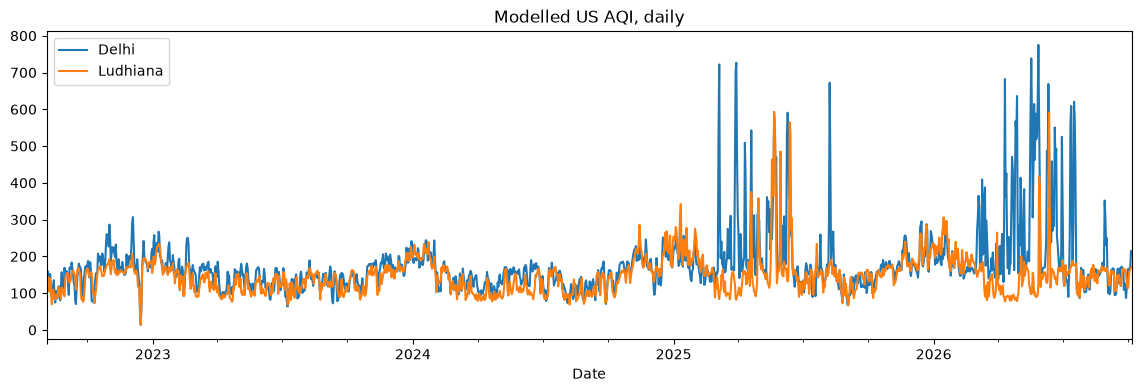

In [34]:
om = pd.read_csv("data/processed/openmeteo_daily.csv", parse_dates=["Date"])

# 1) missing days per city
for c, g in om.groupby("City"):
    full = pd.date_range(g["Date"].min(), g["Date"].max())
    print(c, "missing days:", len(full) - g["Date"].nunique())

# 2) missing values per column
print("\n% missing per column:")
print((om.isna().mean() * 100).round(1))

# 3) average US AQI per year and city
om["year"] = om["Date"].dt.year
print("\nAverage US AQI per year:")
print(om.pivot_table(index="year", columns="City", values="us_aqi",
                     aggfunc="mean").round(0))

# 4) plot Delhi and Ludhiana
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(14, 4))
for c in ["Delhi", "Ludhiana"]:
    om[om["City"] == c].set_index("Date")["us_aqi"].plot(ax=ax, label=c)
ax.legend()
ax.set_title("Modelled US AQI, daily")
plt.show()

In [35]:
om = pd.read_csv("data/processed/openmeteo_daily.csv", parse_dates=["Date"])
om["month"] = om["Date"].dt.to_period("M")
pol = ["us_aqi", "pm2_5", "pm10", "nitrogen_dioxide",
       "sulphur_dioxide", "carbon_monoxide", "ozone"]

for c in ["Gurugram", "Delhi", "Lucknow"]:
    g = om[om["City"] == c].groupby("month")[pol].mean().round(0)
    print(c, "- monthly averages (every 3rd month):")
    print(g.iloc[::3])
    print()

g = om[om["City"] == "Gurugram"]
print("Gurugram: days with us_aqi >= 450 per year:")
print((g["us_aqi"] >= 450).groupby(g["Date"].dt.year).sum())

Gurugram - monthly averages (every 3rd month):
         us_aqi  pm2_5    pm10  nitrogen_dioxide  sulphur_dioxide  \
month                                                               
2022-08   111.0   40.0    79.0              45.0             31.0   
2022-11   193.0  110.0   172.0              83.0             77.0   
2023-02   169.0   86.0   143.0              75.0             61.0   
2023-05   140.0   54.0    98.0              57.0             38.0   
2023-08   154.0   51.0   211.0              29.0             14.0   
2023-11   184.0  104.0   163.0              66.0             42.0   
2024-02   151.0   66.0   114.0              40.0             31.0   
2024-05   222.0   63.0   313.0              35.0             20.0   
2024-08   100.0   32.0    51.0              28.0             18.0   
2024-11   198.0  119.0   155.0              67.0             42.0   
2025-02   160.0   73.0   131.0              39.0             31.0   
2025-05   895.0  140.0   989.0              22.0        

In [36]:
om = pd.read_csv("data/processed/openmeteo_daily.csv", parse_dates=["Date"])
om["month"] = om["Date"].dt.to_period("M")

# 1) monthly PM10 since 2024, side by side
m = om[om["Date"] >= "2024-01-01"].pivot_table(
    index="month", columns="City", values="pm10", aggfunc="mean").round(0)
print("Monthly average PM10:")
print(m[["Gurugram", "Delhi", "Ludhiana", "Amritsar", "Lucknow", "Jaipur"]])

# 2) days with PM10 above 600 per year, all cities
om["year"] = om["Date"].dt.year
print("\nDays with PM10 above 600:")
print((om["pm10"] > 600).groupby([om["City"], om["year"]]).sum().unstack())

Monthly average PM10:
City     Gurugram  Delhi  Ludhiana  Amritsar  Lucknow  Jaipur
month                                                        
2024-01     191.0  180.0     181.0     200.0    152.0    90.0
2024-02     114.0   97.0      87.0      91.0     89.0    66.0
2024-03     186.0  114.0      67.0      65.0     86.0    75.0
2024-04     220.0  113.0      64.0      55.0     87.0    88.0
2024-05     313.0  173.0      94.0      70.0     95.0   101.0
2024-06     326.0  203.0     102.0      86.0    122.0    91.0
2024-07      83.0   81.0      90.0      92.0     45.0    57.0
2024-08      51.0   51.0      50.0      47.0     39.0    30.0
2024-09      74.0   73.0      64.0      67.0     45.0    42.0
2024-10     143.0  133.0      90.0      96.0     81.0    56.0
2024-11     155.0  148.0     140.0     146.0    132.0    70.0
2024-12     109.0  103.0     110.0     117.0     95.0    58.0
2025-01     126.0  128.0     152.0     138.0    114.0    55.0
2025-02     131.0  106.0      93.0      87.0    

In [37]:
import numpy as np

om = pd.read_csv("data/processed/openmeteo_daily.csv", parse_dates=["Date"])

# India (CPCB) PM2.5 sub-index: concentration -> index
conc = [0, 30, 60, 90, 120, 250, 380]
idx  = [0, 50, 100, 200, 300, 400, 500]
om["aqi_pm25"] = np.interp(om["pm2_5"], conc, idx).round()

om["year"] = om["Date"].dt.year
om["month"] = om["Date"].dt.month
show = ["Delhi", "Gurugram", "Ludhiana", "Amritsar", "Lucknow"]

spring = om[om["month"].between(3, 6) & om["City"].isin(show)]
print("Average PM2.5, March to June:")
print(spring.pivot_table(index="year", columns="City",
                         values="pm2_5", aggfunc="mean").round(0))

winter = om[om["month"].isin([11, 12]) & om["City"].isin(show)]
print("\nAverage PM2.5, November to December:")
print(winter.pivot_table(index="year", columns="City",
                         values="pm2_5", aggfunc="mean").round(0))

print("\nDelhi, last 8 days:")
print(om[om["City"] == "Delhi"].tail(8)[["Date", "pm2_5", "pm10", "us_aqi", "aqi_pm25"]])

om.drop(columns=["year", "month"]).to_csv("data/processed/openmeteo_daily.csv", index=False)
print("\nSaved with aqi_pm25 column")

Average PM2.5, March to June:
City  Amritsar  Delhi  Gurugram  Lucknow  Ludhiana
year                                              
2023      39.0   55.0      56.0     42.0      41.0
2024      36.0   49.0      57.0     40.0      37.0
2025      49.0   77.0     126.0     47.0      57.0
2026      43.0   89.0     138.0     55.0      50.0

Average PM2.5, November to December:
City  Amritsar  Delhi  Gurugram  Lucknow  Ludhiana
year                                              
2022      95.0  104.0     109.0     98.0      78.0
2023      89.0   96.0     106.0     81.0      79.0
2024     116.0  108.0     113.0     99.0     110.0
2025     111.0  114.0     119.0    106.0     108.0

Delhi, last 8 days:
           Date       pm2_5        pm10      us_aqi  aqi_pm25
1516 2026-09-29   52.179167  152.758333  113.166667      87.0
1517 2026-09-30   67.933333  250.620833  150.791667     126.0
1518 2026-10-01   77.379167  266.016667  165.833333     158.0
1519 2026-10-02   73.620833  236.979167  163.708333

In [38]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor

om = pd.read_csv("data/processed/openmeteo_daily.csv", parse_dates=["Date"])
test_start = pd.Timestamp("2025-10-01")
extra = ["nitrogen_dioxide", "sulphur_dioxide", "carbon_monoxide", "ozone"]  # PM10 left out on purpose
base_feats = ["lag_0", "lag_1", "lag_2", "lag_3", "lag_7", "roll_7", "month"]
all_feats = base_feats + extra
params = dict(max_depth=3, learning_rate=0.05, max_iter=200, random_state=0)

rows = []
for city, g in om.groupby("City"):
    s = g.set_index("Date").asfreq("D")
    for h in [1, 3, 5, 7]:
        d = s[["pm2_5"] + extra].copy()
        d["lag_0"] = d["pm2_5"]
        for lag in [1, 2, 3, 7]:
            d[f"lag_{lag}"] = d["pm2_5"].shift(lag)
        d["roll_7"] = d["pm2_5"].rolling(7).mean()
        d["month"] = d.index.month
        d["target"] = d["pm2_5"].shift(-h)
        d = d.dropna(subset=["target"] + base_feats)

        gap = pd.Timedelta(days=h)
        tr = d[d.index < test_start - gap]
        te = d[d.index >= test_start]

        ridge = Ridge().fit(tr[base_feats], tr["target"])
        boost = HistGradientBoostingRegressor(**params).fit(
            tr[all_feats], tr["target"] - tr["lag_0"])
        preds = {
            "baseline": te["lag_0"],
            "ridge": pd.Series(ridge.predict(te[base_feats]), index=te.index),
            "boost": te["lag_0"] + boost.predict(te[all_feats]),
        }
        winter = np.isin((te.index + gap).month, [11, 12, 1, 2])
        for name, p in preds.items():
            err = (te["target"] - p).abs()
            rows.append({"city": city, "h": h, "model": name,
                         "mae": err.mean(), "mae_winter": err[winter].mean()})

res = pd.DataFrame(rows)

def gains(col):
    t = res.pivot_table(index=["city", "h"], columns="model", values=col)
    out = pd.DataFrame({m: ((t["baseline"] - t[m]) / t["baseline"] * 100).round()
                        for m in ["ridge", "boost"]})
    return t, out.unstack("h")

t_all, g_all = gains("mae")
t_win, g_win = gains("mae_winter")

print("Baseline error in ug/m3 (all test days):")
print(t_all["baseline"].unstack("h").round(1))
print("\nGain vs same-as-today, ALL test days (%, positive = better):")
print(g_all)
print("\nGain vs same-as-today, WINTER target days Nov-Feb (%):")
print(g_win)

Baseline error in ug/m3 (all test days):
h                      1     3     5     7
city                                      
Amritsar            14.3  23.2  26.8  27.3
Bengaluru            5.5   9.5  10.3  10.8
Chennai              4.8   8.4   9.7  10.9
Delhi               17.6  29.2  31.9  33.1
Gurugram            25.7  39.6  43.9  43.6
Hyderabad            5.9  10.0  11.0  11.8
Jaipur               8.0  12.9  14.3  15.4
Lucknow             11.8  20.0  23.9  24.9
Ludhiana            14.5  23.9  26.4  26.7
Thiruvananthapuram   3.5   6.0   6.7   6.8

Gain vs same-as-today, ALL test days (%, positive = better):
                   ridge                   boost                  
h                      1     3     5     7     1     3     5     7
city                                                              
Amritsar             3.0  12.0  15.0  18.0   0.0   6.0  15.0  13.0
Bengaluru            6.0  11.0  12.0  16.0   6.0  14.0  14.0  18.0
Chennai              2.0   9.0  14.0  19.0  -3

In [39]:
rows = []
for city, g in om.groupby("City"):
    s = g.set_index("Date").asfreq("D")
    for h in [1, 3, 5, 7]:
        d = s[["pm2_5"] + extra].copy()
        d["lag_0"] = d["pm2_5"]
        for lag in [1, 2, 3, 7]:
            d[f"lag_{lag}"] = d["pm2_5"].shift(lag)
        d["roll_7"] = d["pm2_5"].rolling(7).mean()
        d["roll_30"] = d["pm2_5"].rolling(30).mean()
        d["month"] = d.index.month
        d["target"] = d["pm2_5"].shift(-h)
        d = d.dropna(subset=["target", "roll_30"] + base_feats)

        gap = pd.Timedelta(days=h)
        tr = d[d.index < test_start - gap]
        te = d[d.index >= test_start]
        ridge = Ridge().fit(tr[base_feats], tr["target"])

        naive = {"today": te["lag_0"], "mean7": te["roll_7"], "mean30": te["roll_30"]}
        winter = np.isin((te.index + gap).month, [11, 12, 1, 2])

        def mae(p, mask=None):
            e = (te["target"] - p).abs()
            return e.mean() if mask is None else e[mask].mean()

        p_r = pd.Series(ridge.predict(te[base_feats]), index=te.index)
        n_all = {k: mae(v) for k, v in naive.items()}
        n_win = {k: mae(v, winter) for k, v in naive.items()}
        best_all, best_win = min(n_all, key=n_all.get), min(n_win, key=n_win.get)

        rows.append({
            "city": city, "h": h,
            "best_naive": best_all,
            "gain_vs_best_all": (n_all[best_all] - mae(p_r)) / n_all[best_all] * 100,
            "gain_vs_best_winter": (n_win[best_win] - mae(p_r, winter)) / n_win[best_win] * 100,
        })

r2 = pd.DataFrame(rows)
print("Ridge gain vs BEST naive baseline, all test days (%):")
print(r2.pivot(index="city", columns="h", values="gain_vs_best_all").round())
print("\nRidge gain vs BEST naive baseline, winter target days (%):")
print(r2.pivot(index="city", columns="h", values="gain_vs_best_winter").round())
print("\nWhich naive baseline was best:")
print(r2.groupby("h")["best_naive"].value_counts().unstack(fill_value=0))

Ridge gain vs BEST naive baseline, all test days (%):
h                     1    3    5    7
city                                  
Amritsar            3.0  7.0  4.0  6.0
Bengaluru           6.0 -0.0 -5.0 -5.0
Chennai             2.0  5.0 -1.0 -4.0
Delhi               5.0  7.0  6.0  3.0
Gurugram            8.0  8.0  7.0  7.0
Hyderabad           7.0  4.0  1.0 -2.0
Jaipur              4.0  9.0  9.0  8.0
Lucknow             3.0  9.0  9.0  9.0
Ludhiana            8.0  3.0  3.0  8.0
Thiruvananthapuram  4.0  3.0  1.0  1.0

Ridge gain vs BEST naive baseline, winter target days (%):
h                      1     3     5     7
city                                      
Amritsar             1.0   4.0   1.0   3.0
Bengaluru            8.0   3.0  -2.0  -8.0
Chennai              7.0   2.0   0.0  -2.0
Delhi                9.0   3.0   2.0   7.0
Gurugram            10.0   4.0   4.0   6.0
Hyderabad            9.0   3.0 -12.0 -13.0
Jaipur               7.0   6.0   4.0   7.0
Lucknow              8.0  14.0 

In [40]:
folds = {"fold1": ("2024-10-01", "2025-10-01"),
         "fold2": ("2025-10-01", "2026-10-07")}
naive_for = {1: "lag_0", 3: "roll_7", 5: "roll_7", 7: "roll_30"}

rows = []
for city, g in om.groupby("City"):
    s = g.set_index("Date").asfreq("D")
    for h in [1, 3, 5, 7]:
        d = s[["pm2_5"]].copy()
        d["lag_0"] = d["pm2_5"]
        for lag in [1, 2, 3, 7]:
            d[f"lag_{lag}"] = d["pm2_5"].shift(lag)
        d["roll_7"] = d["pm2_5"].rolling(7).mean()
        d["roll_30"] = d["pm2_5"].rolling(30).mean()
        d["month"] = d.index.month
        d["target"] = d["pm2_5"].shift(-h)
        d = d.dropna(subset=["target", "roll_30"] + base_feats)

        gap = pd.Timedelta(days=h)
        for name, (a, b) in folds.items():
            a, b = pd.Timestamp(a), pd.Timestamp(b)
            tr = d[d.index < a - gap]
            te = d[(d.index >= a) & (d.index < b)]
            m = Ridge().fit(tr[base_feats], tr["target"])
            e_model = (te["target"] - m.predict(te[base_feats])).abs().mean()
            e_naive = (te["target"] - te[naive_for[h]]).abs().mean()
            rows.append({"city": city, "h": h, "fold": name,
                         "gain": (e_naive - e_model) / e_naive * 100})

f = pd.DataFrame(rows)
for name in folds:
    print(f"Ridge gain vs fixed naive baseline, {name} (%):")
    print(f[f["fold"] == name].pivot(index="city", columns="h", values="gain").round())
    print()

w = f.pivot_table(index=["city", "h"], columns="fold", values="gain")
w["use_ridge"] = (w["fold1"] > 2) & (w["fold2"] > 2)
policy_pm25 = w["use_ridge"].unstack("h")
print("Use Ridge (wins by more than 2% in BOTH years):")
print(policy_pm25)
print("\nCells using Ridge:", int(w["use_ridge"].sum()), "of", len(w))

os.makedirs("models", exist_ok=True)
w.reset_index().to_csv("models/policy_pm25.csv", index=False)
print("Saved models/policy_pm25.csv")

Ridge gain vs fixed naive baseline, fold1 (%):
h                     1     3     5     7
city                                     
Amritsar            8.0  -1.0   4.0  14.0
Bengaluru           3.0   9.0   9.0  -7.0
Chennai             3.0  13.0   8.0 -11.0
Delhi               4.0   8.0   7.0  13.0
Gurugram            6.0  10.0   8.0  11.0
Hyderabad           1.0  12.0  10.0  -9.0
Jaipur              5.0   8.0  10.0   4.0
Lucknow             3.0  11.0   9.0  10.0
Ludhiana            5.0   7.0  10.0  21.0
Thiruvananthapuram  6.0   3.0   3.0  -7.0

Ridge gain vs fixed naive baseline, fold2 (%):
h                     1     3    5     7
city                                    
Amritsar            3.0   7.0  4.0  16.0
Bengaluru           6.0   6.0  3.0  -5.0
Chennai             2.0  12.0  8.0  -4.0
Delhi               5.0   7.0  8.0   3.0
Gurugram            8.0   8.0  7.0   7.0
Hyderabad           7.0   4.0  1.0  -2.0
Jaipur              4.0   9.0  9.0   8.0
Lucknow             3.0  12.0  9

In [41]:
pol = pd.read_csv("models/policy_pm25.csv")
use = {(r.city, int(r.h)): bool(r.use_ridge) for r in pol.itertuples()}

labels = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
def category(a):
    return labels[int(np.searchsorted([50, 100, 200, 300, 400], a, side="left"))]

rows = []
for city, g in om.groupby("City"):
    s = g.set_index("Date").asfreq("D")
    d = s[["pm2_5"]].copy()
    d["lag_0"] = d["pm2_5"]
    for lag in [1, 2, 3, 7]:
        d[f"lag_{lag}"] = d["pm2_5"].shift(lag)
    d["roll_7"] = d["pm2_5"].rolling(7).mean()
    d["roll_30"] = d["pm2_5"].rolling(30).mean()
    d["month"] = d.index.month

    last = d.dropna(subset=base_feats + ["roll_30"]).iloc[[-1]]
    issue = last.index[0]

    for h in [1, 3, 5, 7]:
        dh = d.copy()
        dh["target"] = dh["pm2_5"].shift(-h)
        tr = dh.dropna(subset=["target", "roll_30"] + base_feats)

        if use[(city, h)]:
            f = float(Ridge().fit(tr[base_feats], tr["target"]).predict(last[base_feats])[0])
            method = "ridge"
        else:
            f = float(last[naive_for[h]].iloc[0])
            method = naive_for[h]
        f = max(f, 0.0)
        aqi = float(np.interp(f, conc, idx))
        rows.append({"city": city, "issue_date": issue.date(),
                     "target_date": (issue + pd.Timedelta(days=h)).date(),
                     "h": h, "method": method,
                     "pm25_today": round(float(last["lag_0"].iloc[0]), 1),
                     "pm25_forecast": round(f, 1),
                     "aqi": round(aqi), "category": category(aqi)})

fc = pd.DataFrame(rows)
fc.to_csv("data/processed/forecast_latest.csv", index=False)

print("Forecast made from data up to:", fc["issue_date"].iloc[0])
print("\nPM2.5-based AQI forecast:")
print(fc.pivot(index="city", columns="h", values="aqi"))
print("\nDelhi and Ludhiana in detail:")
print(fc[fc["city"].isin(["Delhi", "Ludhiana"])].drop(columns="issue_date").to_string(index=False))

Forecast made from data up to: 2026-10-06

PM2.5-based AQI forecast:
h                     1    3    5    7
city                                  
Amritsar             90  132  136  130
Bengaluru            46   45   45   31
Chennai              26   34   38   35
Delhi               163  167  171  168
Gurugram            237  213  204  206
Hyderabad            67   63   72   49
Jaipur               32   40   45   49
Lucknow              85   93   99  103
Ludhiana            172  150  154  152
Thiruvananthapuram   34   29   30   21

Delhi and Ludhiana in detail:
    city target_date  h method  pm25_today  pm25_forecast  aqi category
   Delhi  2026-10-07  1  ridge        84.6           78.8  163 Moderate
   Delhi  2026-10-09  3  ridge        84.6           80.0  167 Moderate
   Delhi  2026-10-11  5  ridge        84.6           81.4  171 Moderate
   Delhi  2026-10-13  7  ridge        84.6           80.3  168 Moderate
Ludhiana  2026-10-07  1  ridge        87.1           81.5  172 Moderate


In [42]:
fc = pd.read_csv("data/processed/forecast_latest.csv")
issue = pd.Timestamp(fc["issue_date"].iloc[0])

rows = []
for name, (lat, lon) in cities.items():
    p = {"latitude": lat, "longitude": lon, "hourly": "pm2_5",
         "forecast_days": 7, "timezone": "Asia/Kolkata"}
    r = requests.get(url, params=p, timeout=60)
    r.raise_for_status()
    x = pd.DataFrame(r.json()["hourly"])
    x["time"] = pd.to_datetime(x["time"])
    daily = x.set_index("time")["pm2_5"].resample("D").mean()
    for h in [1, 3, 5, 7]:
        rows.append({"city": name, "h": h,
                     "open_meteo": round(float(daily.get(issue + pd.Timedelta(days=h), np.nan)), 1)})
    time.sleep(1)

cmp_ = pd.DataFrame(rows).merge(fc[["city", "h", "pm25_today", "pm25_forecast"]],
                                on=["city", "h"])
cmp_["diff"] = (cmp_["pm25_forecast"] - cmp_["open_meteo"]).round(1)

print("Our forecast (PM2.5, ug/m3):")
print(cmp_.pivot(index="city", columns="h", values="pm25_forecast"))
print("\nOpen-Meteo's own forecast:")
print(cmp_.pivot(index="city", columns="h", values="open_meteo"))
print("\nPM2.5 today (last full day):")
print(cmp_.drop_duplicates("city").set_index("city")["pm25_today"])

Our forecast (PM2.5, ug/m3):
h                       1     3     5     7
city                                       
Amritsar             54.1  69.6  70.7  68.9
Bengaluru            27.8  27.0  27.0  18.7
Chennai              15.4  20.3  22.8  21.2
Delhi                78.8  80.0  81.4  80.3
Gurugram            101.2  93.8  91.3  91.9
Hyderabad            40.1  38.0  43.1  29.3
Jaipur               19.3  23.7  27.2  29.6
Lucknow              50.9  55.8  59.7  60.8
Ludhiana             81.5  75.0  76.1  75.5
Thiruvananthapuram   20.5  17.3  18.0  12.3

Open-Meteo's own forecast:
h                       1      3     5   7
city                                      
Amritsar             40.9   55.3  52.0 NaN
Bengaluru            29.7   23.7  28.2 NaN
Chennai              11.6   14.2  23.6 NaN
Delhi                72.9   77.0  54.0 NaN
Gurugram            104.1  116.6  85.2 NaN
Hyderabad            38.8   39.1  28.3 NaN
Jaipur               16.5   19.2  27.2 NaN
Lucknow              53.6   

In [43]:
%run update.py

New city-days added: 0 | data now ends: 2026-10-06
Forecast made from data up to: 2026-10-06
Rows in forecast_history.csv: 40
target_date  h method  pm25_forecast  open_meteo_pm25  aqi category
 2026-10-07  1  ridge           78.8             72.9  163 Moderate
 2026-10-09  3  ridge           80.0             77.0  167 Moderate
 2026-10-11  5  ridge           81.4             54.0  171 Moderate
 2026-10-13  7  ridge           80.3              NaN  168 Moderate
